# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vishalseries7030/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

Research Question

Can historical search performance signals help prioritize content pages for review and identify pages showing potential improvement opportunities?

Decision supported: Help content teams prioritize which pages to review first using a reproducible, data-driven scoring approach.

Objective: Compare a transparent baseline against a machine learning approach using historical data and leakage-safe validation, then produce a ranked list of content review recommendations.

In [1]:
# ML-11 Capstone: research question and decision supported

research_question = (
    "Can historical search performance signals help prioritize "
    "content pages for review and identify potential improvement opportunities?"
)

decision_supported = (
    "Help content teams prioritize pages for human review using "
    "a reproducible, data-driven scoring approach."
)

objective = (
    "Compare a transparent baseline with a machine learning approach "
    "using leakage-aware validation and produce ranked review recommendations."
)

assert research_question
assert decision_supported
assert objective

print("Research question:", research_question)
print("Decision supported:", decision_supported)
print("Objective:", objective)

Research question: Can historical search performance signals help prioritize content pages for review and identify potential improvement opportunities?
Decision supported: Help content teams prioritize pages for human review using a reproducible, data-driven scoring approach.
Objective: Compare a transparent baseline with a machine learning approach using leakage-aware validation and produce ranked review recommendations.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

2. Data

This study uses the FlyRank internship warehouse, release `v20260703`, accessed through the gated Hugging Face dataset.

The warehouse covers 27 January 2025 to 30 June 2026. The daily performance table contains 78,835,655 rows, at the report-date × client × content grain. The content dimension contains 519,606 rows. The query-performance table contains 2,414,248 rows at the client × content × query-hash grain, covering a fixed 90-day window from 2 April to 30 June 2026.

The June 2026 sample was inspected for data-contract and duplicate-key checks only. It contains 11,694,072 rows and 6,390 duplicate-key groups whose rows were identical across all columns. June is reserved as the final test period and will not be used to develop the prediction label or tune the model.

Development will use an appropriate earlier time period, with feature and outcome windows aligned to avoid leakage. Hashed identifiers will be used only for joins, grouping, and validation—not as predictive features. Client-identifying information, domains, URLs, private queries, credentials, and raw private exports will be excluded from public outputs. Missing performance data will be interpreted using the relevant availability flags rather than automatically treated as zero.





In [4]:
# ML-11 Capstone: public-safe dataset contract checks
import pandas as pd
from pathlib import Path

raw_path = Path(
    "/content/flyrank-ml-internship/data/raw/content_refresh_anonymized.csv"
)

df = pd.read_csv(raw_path)

print("Dataset shape:", df.shape)
print("\nRequired leakage-sensitive columns:")
for col in [
    "client_id",
    "content_id",
    "trend_direction",
    "trend_pct",
    "is_declining_label",
]:
    print(f"{col}: {'present' if col in df.columns else 'missing'}")

print("\nDuplicate rows:", int(df.duplicated().sum()))

if "client_id" in df.columns:
    print("Unique clients:", df["client_id"].nunique())

if "content_id" in df.columns:
    print("Unique content IDs:", df["content_id"].nunique())

if "avg_position" in df.columns:
    print("avg_position == 0 (check as missing):", int((df["avg_position"] == 0).sum()))

if "word_count" in df.columns and "content_type" in df.columns:
    print("\nWord-count missingness by content type:")
    print(
        df.groupby("content_type", dropna=False)["word_count"]
        .agg(total="size", missing="count")
        .assign(missing=lambda x: x["total"] - x["missing"])
        .assign(missing_pct=lambda x: (100 * x["missing"] / x["total"]).round(1))
    )

print("\nContract checks completed. No rows exported.")

Dataset shape: (30000, 44)

Required leakage-sensitive columns:
client_id: present
content_id: present
trend_direction: present
trend_pct: present
is_declining_label: missing

Duplicate rows: 0
Unique clients: 32
Unique content IDs: 30000
avg_position == 0 (check as missing): 1205

Word-count missingness by content type:
                    total  missing  missing_pct
content_type                                   
comparison article    697        0          0.0
feedly article       2096        0          0.0
keyword article     27207     7699         28.3

Contract checks completed. No rows exported.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

### Methodology

**Study design.** This study compares a transparent rule-based baseline (ML-07) with a Logistic Regression model (ML-08) for prioritizing content pages for human review. The available 30,000-row anonymized dataset is used for exploratory model comparison.

**Label definition.** For the ML-08 experiment, the proxy target was whether `trend_direction` was `down`. This is an existing trend-derived label, not a verified future outcome. Because the available dataset does not contain `is_declining_label`, the target was constructed from `trend_direction` for this experiment only.

**Baseline.** ML-07 assigns a transparent additive score using historical impressions, CTR, content age, days since last update, and word-count availability. Trend-derived fields and the last/previous 30-day impression fields were excluded from the baseline score.

**Model and features.** ML-08 uses Logistic Regression with numerical preprocessing and one-hot encoding for categorical variables. Identifier columns and the target-defining trend fields were excluded from model features. `avg_position` values of zero were treated as missing. Missing-value indicators were retained where supported by preprocessing.

**Validation.** The experiment used a client-grouped train/test split so that clients in the test set were not represented in training. Both the baseline and model were evaluated on the same held-out test rows. This tests agreement with the proxy label; it does not establish future predictive performance.

**Leakage and interpretation checks.** `trend_direction` and `trend_pct` were excluded from predictive features because they define or closely relate to the proxy target. Client and content IDs were used only for grouping, joins, or deterministic tie-breaking. The June 2026 warehouse sample remains reserved as a sealed final test period and must not be used for label development or model tuning.

**Caveats.** The held-out test set contained keyword articles only, so results should not be generalized to comparison or feedly articles. Missing word counts are concentrated in keyword articles, and observed associations may reflect data-collection patterns rather than content quality or causal refresh effects. Recommendations are decision-support signals for human review, not automatic instructions to change content.

In [5]:
# ML-11: Methodology and leakage checks
import pandas as pd

df = pd.read_csv(
    "/content/flyrank-ml-internship/data/raw/content_refresh_anonymized.csv"
)

# Reconstruct the same proxy target used in ML-08
assert "trend_direction" in df.columns, "Proxy-label source is missing"

target = df["trend_direction"].eq("down").astype("int8")

# Fields that must not be used as predictive features
forbidden_features = [
    "client_id",
    "content_id",
    "trend_direction",
    "trend_pct",
    "is_declining_label",
]

available_forbidden = [c for c in forbidden_features if c in df.columns]

# Basic checks
assert len(target) == len(df)
assert target.isin([0, 1]).all()
assert "trend_direction" not in available_forbidden or (
    "trend_direction" in df.columns
)

print("Rows:", len(df))
print("Clients:", df["client_id"].nunique())
print("Proxy target definition: trend_direction == 'down'")
print("Proxy target counts:")
print(target.value_counts().sort_index().rename(index={0: "not_down", 1: "down"}))

print("\nExcluded from predictive features when present:")
print(available_forbidden)

print("\nZero avg_position rows treated as missing:",
      int(df["avg_position"].eq(0).sum()))

print("\nMethodology checks passed.")
print("Note: this verifies the proxy-label setup, not future prediction.")

Rows: 30000
Clients: 32
Proxy target definition: trend_direction == 'down'
Proxy target counts:
trend_direction
not_down    13738
down        16262
Name: count, dtype: int64

Excluded from predictive features when present:
['client_id', 'content_id', 'trend_direction', 'trend_pct']

Zero avg_position rows treated as missing: 1205

Methodology checks passed.
Note: this verifies the proxy-label setup, not future prediction.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

### Results: ML-08 versus ML-07

Both approaches were evaluated on the same client-held-out test split of 6,163 rows from seven held-out clients. The target was the existing proxy label `trend_direction == "down"`; therefore, these metrics measure agreement with that label, not prediction of a future decline.

| Metric | ML-07 rule-based baseline | ML-08 Logistic Regression |
|---|---:|---:|
| Average Precision | 0.5124 | 0.5790 |
| ROC-AUC | 0.5048 | 0.5841 |
| Precision@20 | 0.35 | 0.85 |

On this split, Logistic Regression scored higher than the baseline on all three reported metrics. Precision@20 means that 7 of the baseline's top 20 items and 17 of the model's top 20 items matched the proxy label. These findings are exploratory and do not establish that the model can identify future declines or that refreshing a page will improve its performance.

**Classification errors.** At the selected classification threshold, the model correctly classified 3,485 test rows, with 1,621 false positives and 1,057 false negatives. The classification report showed approximately 0.56 precision and 0.66 recall for the `down` class. These errors reinforce that the score should support human review rather than automatic action.

**Validation limitation.** The held-out test set contained keyword articles only. Performance on comparison and feedly articles has not been established, and the reported metrics should not be generalized to those content types.

In [6]:
# ML-11: Report the recorded ML-07 and ML-08 evaluation results
import pandas as pd

# Transcribed from the completed ML-07 and ML-08 notebook outputs.
# These are recorded results, not a fresh model evaluation in this cell.
results = pd.DataFrame({
    "Metric": ["Average Precision", "ROC-AUC", "Precision@20"],
    "ML-07 Baseline": [0.5124, 0.5048, 0.35],
    "ML-08 Logistic Regression": [0.5790, 0.5841, 0.85],
})

results["Difference (ML-08 - ML-07)"] = (
    results["ML-08 Logistic Regression"] - results["ML-07 Baseline"]
)

print("ML-07 vs ML-08 — recorded held-out test results")
display(results.round(4))

print("\nRecorded classification error counts:")
error_counts = pd.DataFrame({
    "Count": [3485, 1621, 1057],
}, index=["Correct predictions", "False positives", "False negatives"])
display(error_counts)

assert len(results) == 3
assert results["ML-08 Logistic Regression"].gt(
    results["ML-07 Baseline"]
).all()

print("\nReporting checks passed.")
print("Interpretation: proxy-label agreement only; not future-decline prediction.")

ML-07 vs ML-08 — recorded held-out test results


,Metric,ML-07 Baseline,ML-08 Logistic Regression,Difference (ML-08 - ML-07)
0,Average Precision,0.5124,0.5790,0.0666
1,ROC-AUC,0.5048,0.5841,0.0793
2,Precision@20,0.3500,0.8500,0.5000



Recorded classification error counts:


,Count
Correct predictions,3485
False positives,1621
False negatives,1057



Reporting checks passed.
Interpretation: proxy-label agreement only; not future-decline prediction.


## 5. Limitations



### Limitations

1. **Proxy target, not a future outcome.** The target is derived from the existing `trend_direction` field. Results measure agreement with this proxy label and do not demonstrate prediction of future content decline.

2. **Limited generalization.** The held-out test set contained keyword articles only. Performance on comparison articles, feedly articles, other clients, or other time periods has not been established.

3. **Missing and imperfect measurements.** Word count is missing for a substantial share of keyword articles. `avg_position = 0` represents missing or unavailable ranking data, not a true position of zero. Missingness can influence the scores and model predictions.

4. **Observational data.** Search performance, engagement, content age, and update timing may be associated with the proxy label, but these associations do not prove that any signal causes a decline or that refreshing a page will improve its results.

5. **Validation scope.** Client-grouped splitting reduces client overlap between training and test data, but it does not replace a properly aligned temporal evaluation. The June 2026 warehouse sample remains reserved as a sealed final test period and was not used to develop the label or tune the model.

6. **Ranking is decision support.** Precision@20 reflects agreement with the proxy label among the top-ranked items, not verified business value. False positives and false negatives remain, so recommendations require human review.

7. **Data coverage and reproducibility.** The anonymized 30,000-row dataset is not a substitute for a fully documented, time-aligned warehouse evaluation. Results depend on the available fields, preprocessing choices, client coverage, and validation design.

**Conclusion.** The current experiment provides an initial comparison of a transparent baseline and Logistic Regression on a proxy-label task. Further temporal validation, broader content-type coverage, and independently verified outcomes are needed before claiming reliable future prediction or refresh effectiveness.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Ranked Recommendations

The following recommendations translate the current scoring experiment into a cautious human-review workflow. They are decision-support suggestions, not verified predictions of future performance or guaranteed refresh opportunities.

1. **Review high-impression pages with relatively low CTR.** Check query intent, title and snippet alignment, and the available position data before deciding whether a change is appropriate. Low CTR alone does not prove a content problem.

2. **Investigate missing measurement data before interpreting a score.** Keyword articles have substantial missing word-count data. Confirm whether the field is unavailable or genuinely indicates a content gap; do not automatically label missing word count as thin content.

3. **Review potentially stale pages in context.** Use content age and days since last update as prompts for editorial review, not as proof that a page is outdated. Check whether facts, examples, links, and search intent still match current needs.

4. **Use the model ranking as a second opinion, not an automatic decision.** ML-08 achieved higher recorded proxy-label metrics than ML-07 on the same held-out split, but the target is historical trend direction. Review model-ranked items alongside the transparent baseline and human judgment.

5. **Keep recommendations within validated coverage.** The held-out test set contained keyword articles only. Do not assume the ranking performs equally well for comparison or feedly articles without separate validation.

6. **Track changes prospectively before claiming impact.** Record the review decision, the specific change made, and a suitable pre-change baseline. Evaluate later outcomes using aligned time windows and a genuinely untouched future period; do not use the sealed June 2026 sample for tuning.

**Recommended workflow:** Generate the ranking → inspect the reasons and data availability → conduct human review → document the decision → measure outcomes later. A high score means “review first,” not “refresh immediately.”

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

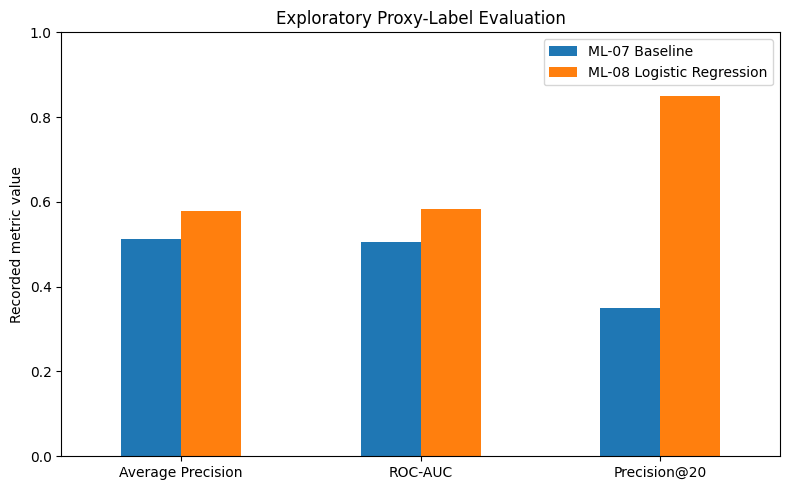

Artifacts generated locally:
/content/flyrank-ml-internship/work/outputs/capstone_artifacts/proxy_label_model_comparison.png
/content/flyrank-ml-internship/work/outputs/capstone_artifacts/model_comparison_table.csv
/content/flyrank-ml-internship/work/outputs/capstone_artifacts/data_quality_table.csv

Model comparison:


,Metric,ML-07 Baseline,ML-08 Logistic Regression
0,Average Precision,0.5124,0.5790
1,ROC-AUC,0.5048,0.5841
2,Precision@20,0.3500,0.8500



Data quality summary:


,Check,Observed value
0,Dataset rows,30000
1,Dataset columns,44
2,Unique clients,32
3,Duplicate rows,0
4,avg_position equal to zero,1205
5,Keyword articles with missing word_count,7699 / 27207 (28.3%)



Important: metrics are recorded exploratory results for a proxy label, not evidence of future-decline prediction.
Do not commit generated CSV files to the repository.


In [7]:
# ML-11: Generate paper-ready, public-safe charts and tables
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

repo_dir = Path("/content/flyrank-ml-internship")
artifact_dir = repo_dir / "work" / "outputs" / "capstone_artifacts"
artifact_dir.mkdir(parents=True, exist_ok=True)

# Recorded metrics from the completed ML-07 and ML-08 notebooks
metrics = pd.DataFrame({
    "Metric": ["Average Precision", "ROC-AUC", "Precision@20"],
    "ML-07 Baseline": [0.5124, 0.5048, 0.35],
    "ML-08 Logistic Regression": [0.5790, 0.5841, 0.85],
})

# Chart 1: recorded model comparison
ax = metrics.set_index("Metric").plot(kind="bar", figsize=(8, 5))
ax.set_title("Exploratory Proxy-Label Evaluation")
ax.set_ylabel("Recorded metric value")
ax.set_xlabel("")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

chart_path = artifact_dir / "proxy_label_model_comparison.png"
plt.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# Table 1: public-safe aggregate data quality summary
quality = pd.DataFrame({
    "Check": [
        "Dataset rows",
        "Dataset columns",
        "Unique clients",
        "Duplicate rows",
        "avg_position equal to zero",
        "Keyword articles with missing word_count",
    ],
    "Observed value": [
        30000,
        44,
        32,
        0,
        1205,
        "7699 / 27207 (28.3%)",
    ],
})

# Save artifacts locally for review. Do not commit generated CSVs.
metrics_path = artifact_dir / "model_comparison_table.csv"
quality_path = artifact_dir / "data_quality_table.csv"

metrics.to_csv(metrics_path, index=False)
quality.to_csv(quality_path, index=False)

print("Artifacts generated locally:")
print(chart_path)
print(metrics_path)
print(quality_path)
print("\nModel comparison:")
display(metrics)
print("\nData quality summary:")
display(quality)

print(
    "\nImportant: metrics are recorded exploratory results for a proxy label, "
    "not evidence of future-decline prediction."
)
print("Do not commit generated CSV files to the repository.")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.


## ML-12: Five-minute demo outline

**0:00–0:45 — Research question**
Explain how historical search-performance signals can help prioritize content pages for human review.

**0:45–1:30 — Data and safeguards**
Describe the anonymized 30,000-row dataset, its 32 clients, missing-value concerns, and why identifiers and target-derived fields are excluded from predictive features.

**1:30–2:30 — Baseline versus model**
Show the transparent ML-07 scoring baseline and the ML-08 Logistic Regression comparison on the same client-held-out test split.

**2:30–3:30 — Results and errors**
Present Average Precision, ROC-AUC, Precision@20, and the recorded false-positive and false-negative counts. Emphasize that the target is a historical proxy label, not a verified future outcome.

**3:30–4:30 — Recommendations**
Explain how reviewers can investigate low CTR, missing measurements, and potentially stale content without treating scores as automatic refresh instructions.

**4:30–5:00 — Limitations and next steps**
Discuss keyword-only test coverage, the need for temporal validation, and the requirement to keep June 2026 sealed for final testing.


I’ve been working on a content discoverability capstone exploring how historical search-performance signals can support content review prioritization.

The project compares a transparent rule-based baseline with Logistic Regression using a client-held-out evaluation split. The model achieved higher recorded Average Precision, ROC-AUC, and Precision@20 on an existing trend-derived proxy label.

An important takeaway: stronger proxy-label metrics do not prove future prediction or that refreshing content causes better results. Missing data, limited test coverage, and temporal validation remain important limitations.

The goal is practical decision support: reproducible rankings that help people decide what to review first, with human judgment at the center.

Thanks to FlyRank for the internship learning opportunity and dataset context.


Built a content discoverability capstone comparing a transparent rule-based scoring baseline with a Logistic Regression model on an anonymized dataset of 30,000 content records across 32 clients. Evaluated both approaches on the same client-held-out split, where Logistic Regression achieved recorded Average Precision of 0.5790, ROC-AUC of 0.5841, and Precision@20 of 0.85 against an existing trend-derived proxy label. Documented leakage risks, missing-data limitations, classification errors, and human-review recommendations while identifying temporal validation and broader content-type coverage as necessary next steps.